In [1]:
import pandas as pd
import pylab as pl
import numpy as np
import scipy.optimize as opt
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
import os
os.chdir("D:/gus6e/Documents")
cell_df = pd.read_csv("cell_samples.csv")
cell_df

,ID,Clump,UnifSize,UnifShape,MargAdh,SingEpiSize,BareNuc,BlandChrom,NormNucl,Mit,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2
...,...,...,...,...,...,...,...,...,...,...,...
694,776715,3,1,1,1,3,2,1,1,1,2
695,841769,2,1,1,1,2,1,1,1,1,2
696,888820,5,10,10,3,7,3,8,10,2,4
697,897471,4,8,6,4,3,4,10,6,1,4


In [4]:
cell_df["Class"] = cell_df["Class"].replace([2],0) # Tumor Benigno
cell_df["Class"] = cell_df["Class"].replace([4],1) # Tumor maligno
cell_df

,ID,Clump,UnifSize,UnifShape,MargAdh,SingEpiSize,BareNuc,BlandChrom,NormNucl,Mit,Class
0,1000025,5,1,1,1,2,1,3,1,1,0
1,1002945,5,4,4,5,7,10,3,2,1,0
2,1015425,3,1,1,1,2,2,3,1,1,0
3,1016277,6,8,8,1,3,4,3,7,1,0
4,1017023,4,1,1,3,2,1,3,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...
694,776715,3,1,1,1,3,2,1,1,1,0
695,841769,2,1,1,1,2,1,1,1,1,0
696,888820,5,10,10,3,7,3,8,10,2,1
697,897471,4,8,6,4,3,4,10,6,1,1


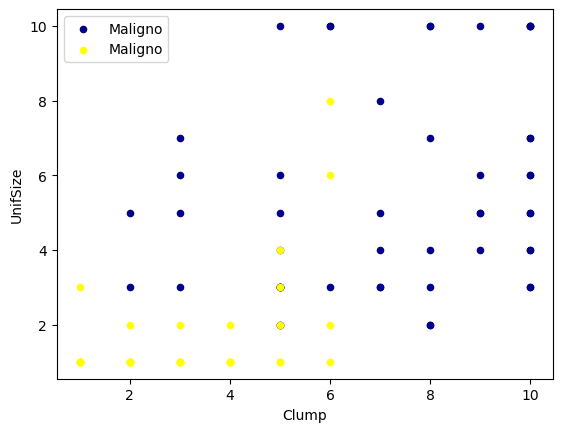

In [14]:
ax = cell_df[cell_df["Class"] == 1][0:50].plot(kind = "scatter", x = "Clump", y = "UnifSize", color = "DarkBlue", label = "Maligno");
ax = cell_df[cell_df["Class"] == 0][0:50].plot(kind = "scatter", x = "Clump", y = "UnifSize", color = "Yellow", label = "Maligno", ax = ax);
plt.show()

In [17]:
# Pre-Procesamiento de datos y selección
cell_df.dtypes

ID              int64
Clump           int64
UnifSize        int64
UnifShape       int64
MargAdh         int64
SingEpiSize     int64
BareNuc        object
BlandChrom      int64
NormNucl        int64
Mit             int64
Class           int64
dtype: object

In [20]:
# Eliminación de renglones no numpericos en BareNuc
cell_df = cell_df[pd.to_numeric(cell_df["BareNuc"], errors = "coerce").notnull()]
cell_df["BareNuc"] = cell_df["BareNuc"].astype("int")
cell_df.dtypes

ID             int64
Clump          int64
UnifSize       int64
UnifShape      int64
MargAdh        int64
SingEpiSize    int64
BareNuc        int64
BlandChrom     int64
NormNucl       int64
Mit            int64
Class          int64
dtype: object

In [23]:
feature_df = cell_df[["Clump", "UnifSize", "UnifShape", "MargAdh", "SingEpiSize", "BareNuc", "BlandChrom", "NormNucl", "Mit"]]
x = np.asarray(feature_df)
x[0:5]

array([[ 5,  1,  1,  1,  2,  1,  3,  1,  1],
       [ 5,  4,  4,  5,  7, 10,  3,  2,  1],
       [ 3,  1,  1,  1,  2,  2,  3,  1,  1],
       [ 6,  8,  8,  1,  3,  4,  3,  7,  1],
       [ 4,  1,  1,  3,  2,  1,  3,  1,  1]])

In [24]:
cell_df["Class"] = cell_df["Class"].astype("int")
y = np.asarray(cell_df["Class"])
y[0:5]

array([0, 0, 0, 0, 0])

In [25]:
# Creación de grupos de entrenamiento y prueba
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size= 0.2, random_state = 4)
print("Grupo de entrenamiento", x_train.shape, y_train.shape)
print("Grupo de prueba",x_test.shape,y_test.shape)

Grupo de entrenamiento (546, 9) (546,)
Grupo de prueba (137, 9) (137,)


# Modelación con SVM
Opciones de Kernel (Transformaciones):
1. Linear
2. Polinomial
3. Radial Basis Function (RBF)
4. Sigmoid

In [26]:
from sklearn import svm
clf = svm.SVC(kernel = "rbf")
clf.fit(x_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [27]:
# Predicción para la base de prueba
yhat = clf.predict(x_test)
yhat[0:5]

array([0, 1, 0, 1, 0])

In [28]:
# Creación de matriz de confusión
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(x)
cm = confusion_matrix(y_test,yhat)
cm

array([[85,  5],
       [ 0, 47]])

In [29]:
y_test

array([0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       0, 0, 0, 0, 1])

In [30]:
yhat

array([0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1,
       0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       0, 0, 0, 0, 1])

In [32]:
z = y_test - yhat
z

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0, -1, -1,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0])

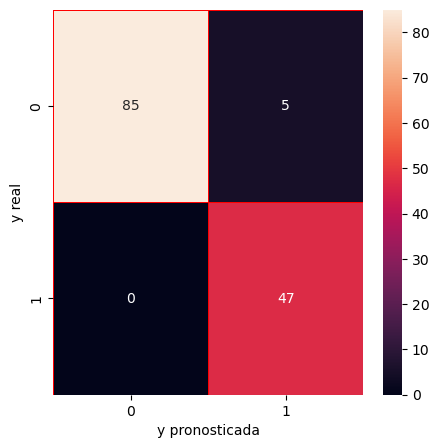

In [36]:
# Visualizar la matriz de confusión
import seaborn as sns
f, ax = plt.subplots(figsize = (5,5))

sns.heatmap(cm,annot=True, linewidths = 0.5, linecolor = "red", fmt = ".0f", ax = ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.show()

# Estadísticas de deseméño

In [39]:
from sklearn.metrics import classification_report
cnf_matrix = confusion_matrix(y_test, yhat,labels = [0,1])
print(classification_report(y_test,yhat))

              precision    recall  f1-score   support

           0       1.00      0.94      0.97        90
           1       0.90      1.00      0.95        47

    accuracy                           0.96       137
   macro avg       0.95      0.97      0.96       137
weighted avg       0.97      0.96      0.96       137



# Determinación de niveles de Precisión (Precision)
- La precisión ("Precision") = Porcentaje de predicciones correctas relativas al total de predicciones.
- Se contesta a la pregunta: ¿Qué porcentaje de las veces que hacemos un pronóstico de cierto tipo éste es correcto?

In [40]:
precisionbenigno = cm[0,0] / (cm[0,0] + cm[1,0])
precisionbenigno

np.float64(1.0)

In [41]:
precisionmaligno = cm[1,1] / (cm[1,1] + cm[0,1])
precisionmaligno

np.float64(0.9038461538461539)

# Determinación de niveles de Recuperación (Recall)
La recuperaciónn (recall) = porcentaje de predicciones correctas relativas al total de valores reales
- El total se calcula por renglón
- Se contesta a la pregunta: ¿Qué porcentaje de las veces que se tiene un valor es de identificarlo?

In [42]:
recallbenigno = cm[0,0] / (cm[0,0] + cm[0,1])
recallbenigno

np.float64(0.9444444444444444)

In [44]:
recallmaligno = cm[1,1] / (cm[1,0] + cm[1,1])
recallmaligno

np.float64(1.0)

# Determinación del Score F1
F1 Score = Media armónica ponderada de la precisión y la recuperación. Cuanto más se acerque a 1, mejor será el modelo.
- F1 Score = 2 * (Precision * Recall) / (Precision + Recall)

In [47]:
f1benigno = 2 * (precisionbenigno * recallbenigno) / (precisionbenigno + recallbenigno)
f1benigno

np.float64(0.9714285714285714)

In [48]:
f1maligno = 2 * (precisionmaligno * recallmaligno) / (precisionmaligno + recallmaligno)
f1maligno

np.float64(0.9494949494949495)

# Determinación de soportes
Soporte = número de observaciones que pertenecen en forma real a cada clase posible (total por renglón)

In [49]:
soportebenigno = cm[0,0] + cm[0,1]
soportebenigno

np.int64(90)

In [50]:
soportemaligno = cm[1,0] + cm[1,1]
soportemaligno

np.int64(47)

# Determinación de la Precisión Global (Accuracy)
Accuracy = Porcentaje de predicciones correctas

In [51]:
correctos = cm[0,0] + cm[1,1]
incorrectos = cm[0,1] + cm[1,0]
precisionglobal = correctos / (correctos + incorrectos)
precisionglobal

np.float64(0.9635036496350365)

# Promedios simples por indicador (Macro Average)
Promedios simples por Precisión, Recuperación y F1 Score

In [53]:
macroavgprecision = (precisionbenigno + precisionmaligno) /2 
macroavgprecision

np.float64(0.9519230769230769)

In [54]:
macroavgrecall = (recallbenigno + recallmaligno) /2 
macroavgrecall

np.float64(0.9722222222222222)

In [55]:
macrof1score = (f1benigno + f1maligno) /2 
macrof1score

np.float64(0.9604617604617605)

# Promedios ponderados por indicador (Weighted average)
Promedios ponderados de acuerdo a soportes por indicador

In [59]:
pesobenigno = soportebenigno / (soportebenigno + soportemaligno)
pesomaligno = soportemaligno / (soportebenigno + soportemaligno)

In [60]:
wavgprecision = precisionbenigno * pesobenigno + precisionmaligno * pesomaligno
wavgprecision

np.float64(0.967012914093206)

In [61]:
wavgrecall = recallbenigno * pesobenigno + recallmaligno * pesomaligno
wavgrecall

np.float64(0.9635036496350364)

In [62]:
wavgf1score = f1benigno * pesobenigno + f1maligno * pesomaligno
wavgf1score

np.float64(0.9639038982104675)

# Prueba de SVM con Kernel Lineal

In [64]:
clf = svm.SVC(kernel = "linear")
clf.fit(x_train,y_train)

yhat = clf.predict(x_test)

#Confusion matrix
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(x)
cm = confusion_matrix(y_test,yhat)
cm

array([[85,  5],
       [ 0, 47]])

In [65]:
from sklearn.metrics import classification_report
# import itertools

cnf_matrix = confusion_matrix(y_test, yhat,labels = [0,1])
# np.set_printoptions(precision=2)

print(classification_report(y_test,yhat))

              precision    recall  f1-score   support

           0       1.00      0.94      0.97        90
           1       0.90      1.00      0.95        47

    accuracy                           0.96       137
   macro avg       0.95      0.97      0.96       137
weighted avg       0.97      0.96      0.96       137



# Prueba de SVM con Kernel Polinomial

In [69]:
clf = svm.SVC(kernel = "poly")
clf.fit(x_train,y_train)

yhat = clf.predict(x_test)

#Confusion matrix
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(x)
cm = confusion_matrix(y_test,yhat)
cm

array([[86,  4],
       [ 0, 47]])

In [70]:
from sklearn.metrics import classification_report
# import itertools

cnf_matrix = confusion_matrix(y_test, yhat,labels = [0,1])
# np.set_printoptions(precision=2)

print(classification_report(y_test,yhat))

              precision    recall  f1-score   support

           0       1.00      0.96      0.98        90
           1       0.92      1.00      0.96        47

    accuracy                           0.97       137
   macro avg       0.96      0.98      0.97       137
weighted avg       0.97      0.97      0.97       137



# Prueba de SVM con Kernel Sigmoide

In [71]:
clf = svm.SVC(kernel = "sigmoid")
clf.fit(x_train,y_train)

yhat = clf.predict(x_test)

#Confusion matrix
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(x)
cm = confusion_matrix(y_test,yhat)
cm

array([[54, 36],
       [47,  0]])

In [72]:
from sklearn.metrics import classification_report
# import itertools

cnf_matrix = confusion_matrix(y_test, yhat,labels = [0,1])
# np.set_printoptions(precision=2)

print(classification_report(y_test,yhat))

              precision    recall  f1-score   support

           0       0.53      0.60      0.57        90
           1       0.00      0.00      0.00        47

    accuracy                           0.39       137
   macro avg       0.27      0.30      0.28       137
weighted avg       0.35      0.39      0.37       137

